# Restaurant Operations - step-by-step project notebook

**Business Analytics Workshop | CookieSensei Labs | Python 3.12**

Work through **what we are doing, why it is useful, how the code works, and what its output means**. The explanations are Markdown cells, and the analysis is in editable Python code cells with saved results. All records are fictional teaching data; monetary values are INR.

Keep this notebook with [restaurant_orders.csv](restaurant_orders.csv) and [app.py](app.py). The [Markdown companion](EXPLANATION.md) provides a continuous reading version. The source application and data used here match revision `c10a61c36fffdd048b69dd78926e6663bc986fce`.

## Learning route: connect commercial activity with service experience

Prepare an operations discussion: **where do sales, waits, and ratings suggest a useful next investigation?** Make the answer reproducible.

Learning objectives:

- Explain the difference between an order, guest appearances, and a unique customer.
- Derive contribution from its available cost definition and describe the costs it excludes.
- Choose totals, means, medians, and tail measures to match an operational question.
- Compare branches and meal periods while checking the number of supporting orders.
- Describe an observed relationship without treating it as proof of cause.
- Translate the analysis into a browser app whose controls and exports refer to the same population.

**Begin with the row grain.** One row in [restaurant_orders.csv](restaurant_orders.csv) is an order, with its branch, meal period, channel, guest count, bill, food cost, wait, and rating. `guests` counts guest appearances; no customer identifier supports deduplicating people. A rating belongs to an order, not separately to each guest.

| Tool | Responsibility in this project | Why it helps you reason |
| --- | --- | --- |
| `Path` | Locate the order file | Makes the input source explicit. |
| pandas | Parse values, filter orders, derive contribution, group and summarize | Keeps each calculation attached to named columns and inspectable intermediate tables. |
| Plotly | Daily sales lines and order-level scatter | Supports both trends and inspection of individual observations. |
| Matplotlib and Seaborn | Bill histogram, wait boxplot, and rating heatmap | Separates distribution shape from subgroup comparisons. |
| Streamlit | Collect selections and render the analysis | Makes the workflow usable without editing Python for every question. |

Workflow: **choose the question, identify the observation unit, select comparable orders, calculate, inspect, and qualify the conclusion**. Missing operational evidence remains missing.

## How to work through this notebook

1. Open `TUTORIAL.ipynb` in JupyterLab or VS Code and select the workshop's Python 3.12 environment.
2. Read the question above a code cell, predict the result, then use **Shift+Enter** to run that cell.
3. Run cells from top to bottom. Python variables stay in the kernel's memory; changing an earlier cell requires rerunning the cells that depend on it.
4. Compare the output with the interpretation underneath. Try the checkpoints before moving on.
5. Use **Restart Kernel and Run All Cells** to reproduce the baseline from a clean session. All executable cells here finish without launching a long-running web server.

The first code cell locates this project and configures notebook chart display. It supports starting in the project folder, the workshop folder, or the repository root. It changes only the kernel's working directory; it does not move any files.

The complete Streamlit teaching script later in this notebook is a **reference code block in a Markdown cell**. Copy it into the stated separate `.py` file to launch its browser interface. The runnable `AppTest` section independently inspects the existing `app.py` and demonstrates a filter rerun inside the notebook. These two execution contexts are explained separately.

Saved figure outputs include embedded PNG previews. In a running JupyterLab or VS Code notebook, Plotly can also display interactive figures. A GitHub preview shows the saved notebook and cannot execute Python. Keep the CSV and app beside the notebook when downloading it for execution. Local JupyterLab users can install the notebook interface with `python -m pip install jupyterlab`; the prepared Cloud Lab already supplies it. Analysis package versions are listed in the [workshop setup](../README.md).

In [1]:
from pathlib import Path                  # Represent a folder or filename as a Python object.
import os                                # Change this kernel's working directory when necessary.
import sys                               # Inspect the Python version selected by the kernel.
from IPython.display import display      # Render tables and figures as notebook outputs.
import matplotlib
import plotly.io as pio

# Support opening the notebook from this folder, the workshop, or the repo root.
notebook_start = Path.cwd()
candidate_folders = [
    notebook_start,
    notebook_start / '06_restaurant_operations',
    notebook_start / 'business_analytics_workshop' / '06_restaurant_operations',
]
PROJECT_DIR = next(
    (folder for folder in candidate_folders
     if (folder / 'restaurant_orders.csv').is_file() and (folder / 'app.py').is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Open this notebook with its sibling CSV and app.py in the project folder.')
PROJECT_DIR = PROJECT_DIR.resolve()
os.chdir(PROJECT_DIR)

# Inline figures belong below their code cells; the Plotly renderer is used by JupyterLab/VS Code.
matplotlib.use('module://matplotlib_inline.backend_inline')
pio.renderers.default = 'plotly_mimetype'
print('Project folder:', PROJECT_DIR.name)
print('CSV and app.py found.')
print('Python:', sys.version.split()[0])

Project folder: 06_restaurant_operations
CSV and app.py found.
Python: 3.12.14


### Python vocabulary you will use repeatedly

| Code pattern | What it means | Why it appears here |
| --- | --- | --- |
| `name = expression` | Calculate a value and give it a name | Later cells can reuse the result |
| `import pandas as pd` | Import a library with a short alias | `pd.read_csv(...)` calls its CSV reader |
| `frame["column"]` | Select one named column as a Series | Apply a calculation to that measure |
| `frame[mask]` | Keep rows whose Boolean condition is `True` | Define the population being analyzed |
| `.method(...)` | Ask an object to perform an operation | `.sum()`, `.mean()` and `.groupby()` answer different questions |
| `# explanation` | A comment Python does not execute | Describe the purpose of the next operation |
| `f"...{value:.2f}..."` | Put a formatted value into a string | Communicate results without changing the underlying value |

Indentation groups statements inside a `for`, `if`, function or `with` block. Brackets, parentheses and column spelling matter. When a cell fails, read the final error message, inspect the named variable or column, and fix the earliest failed step before continuing.

## The business question

A restaurant manager wants to understand sales alongside the service experience. Which branches contribute revenue? Where do orders wait longest? Do lower ratings coincide with longer waits? Which branch/meal-period combinations deserve investigation? A single sales total or average rating cannot answer all of those questions.

This dashboard connects commercial measures with service measures. It separates **bill per order** from **sales per guest**, **food-cost contribution** from **net profit**, and **observed association** from **cause and effect**. Its useful outcome is a better operational question, such as whether comparable dinner orders at a particular branch need a process review. It does not optimize staffing or prove why a rating was low.

One row is **one order**. Guests are counted inside that order. There is no customer identifier for deduplicating repeat visitors, and no staffing, capacity, food-preparation breakdown, or customer-comment field.

| Source field | Meaning and unit |
| --- | --- |
| `order_id`, `date` | Synthetic order identity and order date |
| `branch`, `meal_period`, `channel` | Location, service period, and order channel |
| `guests` | Guests associated with that order |
| `bill_amount`, `food_cost` | Billed sales and recorded food cost, INR |
| `wait_minutes` | Recorded service wait, minutes |
| `rating` | Recorded score, intended range 1-5 |

**Why pandas?** A `DataFrame` gives named columns, row selection, date parsing, group summaries, percentile calculations, correlation, and CSV export in one table-oriented tool. The code can closely match the question: group orders by branch, then sum bills and average waits. Python could do these tasks with loops and dictionaries, but pandas reduces repetitive bookkeeping. It does not decide whether a mean, sum, or denominator makes business sense; that is what the explanations below address.

## Prepare and inspect the source

Use Python 3.12 and the [workshop environment](../README.md). From the repository root in a Linux/macOS terminal:

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install streamlit==1.50.0 pandas==2.2.3 numpy==2.3.5 matplotlib==3.10.8 seaborn==0.13.2 plotly==6.5.2
cd business_analytics_workshop/06_restaurant_operations
```

Use this environment as your notebook kernel, or its Python console. JupyterLab or VS Code notebook support is a separate notebook tool if not already installed. CookieSensei's prepared workspace provides the analysis environment. For a full Windows checkout, use WSL or the Linux Cloud Lab as explained in the [root README](../../README.md), because other phase directories contain `>` in their names. The captured chart PNGs below are already available; ordinary interactive Plotly display does not require an image-export package.

### Step 01 - Import the tools and locate the source

**Question:** Which tools serve the analysis, and can this session see the CSV?

In [2]:
from pathlib import Path             # Locate a local file without hard-coding a machine path.
import pandas as pd                  # Load and analyze rectangular data.
import matplotlib.pyplot as plt      # Make figures, axes, and a histogram.
import seaborn as sns                # Compare distributions and draw a matrix heatmap.
import plotly.express as px          # Make interactive line and scatter charts.

DATA_FILE = Path('restaurant_orders.csv')  # Run notebook cells from this project folder.
print(f'Dataset: {DATA_FILE.name}')
print(f'File exists: {DATA_FILE.is_file()}')

Dataset: restaurant_orders.csv
File exists: True


**Interpretation and reasoning**

pandas handles the records and calculations. The three plotting libraries express different visual views; Streamlit will display them in a browser later. A notebook normally has no `__file__`, so this cell relies on the stated working directory. The original saved app instead uses its own file path to locate the sibling CSV, which is independent of the terminal directory.

### Step 02 - Read actual orders before calculating anything

**Question:** What does one input row really say?

In [3]:
frame = pd.read_csv(DATA_FILE)         # Parse headers and rows into one DataFrame.
print(f'Orders: {len(frame)} | Source columns: {len(frame.columns)}')
print(frame.head(4).to_string(index=False))  # Show a small source sample, not synthetic rows.

Orders: 600 | Source columns: 10
 order_id       date     branch meal_period  channel  guests  bill_amount  food_cost  wait_minutes  rating
DINE-0001 2025-01-01    Central      Dinner Takeaway       1       470.12     102.74            54       3
DINE-0002 2025-01-02 University   Breakfast  Dine in       3      1242.74     381.17            47       3
DINE-0003 2025-01-03    Central       Lunch Delivery       3      1430.24     370.61            34       4
DINE-0004 2025-01-04 University      Dinner  Dine in       6      1858.33     809.89            55       3


### Notebook skill - inspect a table directly

The printed preview above is useful in scripts and text reports. A notebook can also render the DataFrame itself as a table. `head(5)` returns a small view for inspection; it does not replace the full source table. Compare the row labels on the left with any business identifier column.

In [4]:
# Display the same source as a notebook table; keep frame unchanged.
display(frame.head(5))

,order_id,date,branch,meal_period,channel,guests,bill_amount,food_cost,wait_minutes,rating
0,DINE-0001,2025-01-01,Central,Dinner,Takeaway,1,470.12,102.74,54,3
1,DINE-0002,2025-01-02,University,Breakfast,Dine in,3,1242.74,381.17,47,3
2,DINE-0003,2025-01-03,Central,Lunch,Delivery,3,1430.24,370.61,34,4
3,DINE-0004,2025-01-04,University,Dinner,Dine in,6,1858.33,809.89,55,3
4,DINE-0005,2025-01-05,Riverside,Breakfast,Dine in,1,395.84,100.65,6,5


**Interpretation and reasoning**

The first order is Central / Dinner / Takeaway for one guest, with bill INR 470.12, food cost INR 102.74, wait 54 minutes, and rating 3. Those are recorded attributes; the row does not tell us why the wait or score occurred. `head(4)` limits inspection output without changing the full `frame`. The order count is not a count of unique customers.

### Step 03 - Check row identity and the available comparison groups

**Question:** Are repeated orders or unexpected group labels affecting the planned comparisons?

In [5]:
# Check order identity separately from distinct group labels before counting or aggregating.
print(f'Unique order IDs: {frame["order_id"].nunique()}')
print(f'Repeated order IDs: {frame["order_id"].duplicated().sum()}')
for column in ['branch', 'meal_period', 'channel']:
    print(f'{column}: {", ".join(sorted(frame[column].unique()))}')

Unique order IDs: 600
Repeated order IDs: 0
branch: Central, Riverside, University
meal_period: Breakfast, Dinner, Lunch
channel: Delivery, Dine in, Takeaway


**Interpretation and reasoning**

The actual file has 600 distinct order IDs and the three expected grouping dimensions. Checking repeated order IDs is an **extra diagnostic**: the original app reports exact duplicate rows but does not enforce unique IDs. A record count using `.size()` counts rows even if a future CSV repeats an identifier. A unique order ID still does not identify a unique customer across orders.

### Step 04 - Parse dates and required numbers explicitly

**Question:** Can the code treat dates as dates and measured quantities as numbers?

In [6]:
frame['date'] = pd.to_datetime(frame['date'], errors='raise')  # Enable date comparisons/grouping.
numeric_columns = ['guests', 'bill_amount', 'food_cost', 'wait_minutes', 'rating']
for column in numeric_columns:
    frame[column] = pd.to_numeric(frame[column], errors='raise')

print(frame.dtypes.to_string())
print('Date interval:', frame['date'].min().date(), 'to', frame['date'].max().date())

order_id                object
date            datetime64[ns]
branch                  object
meal_period             object
channel                 object
guests                   int64
bill_amount            float64
food_cost              float64
wait_minutes             int64
rating                   int64
Date interval: 2025-01-01 to 2025-04-30


**Interpretation and reasoning**

`errors="raise"` rejects unparseable content rather than silently converting it to missing values. It does not check that guests are positive integers, waits are nonnegative, or ratings fall between one and five. The intended field meaning and its enforced validation are different things. The code uses no direct NumPy operation even though NumPy belongs to the shared environment.

### Step 05 - Validate required records and report source quality

**Question:** Is required input available, and which structural problems can we detect?

In [7]:
required = ['order_id', 'date', 'branch', 'meal_period', 'channel',
            'guests', 'bill_amount', 'food_cost', 'wait_minutes', 'rating']
if not set(required).issubset(frame.columns):
    raise ValueError('The CSV is missing required columns.')
if frame.empty:
    raise ValueError('The CSV contains no rows.')
if frame[required].isna().any().any():  # Missing-cell flags are reduced over both axes.
    raise ValueError('Fill missing required values before analysis.')

quality = pd.DataFrame({'field': frame.columns,
                        'missing': frame.isna().sum().values})
print(quality.to_string(index=False))
print(f'Exact duplicate rows: {frame.duplicated().sum()}')

       field  missing
    order_id        0
        date        0
      branch        0
 meal_period        0
     channel        0
      guests        0
 bill_amount        0
   food_cost        0
wait_minutes        0
      rating        0
Exact duplicate rows: 0


**Interpretation and reasoning**

The bundled file passes these checks. The original app follows the same missing-value policy and displays a useful error before stopping; this notebook lets the exception interrupt the cell. Parsing comes before the schema check, so a missing date header can raise `KeyError` earlier. No values are imputed, no outliers are dropped, and no proof of representativeness follows from the absence of missing cells.

## Filter orders and calculate useful measures

### Checkpoint: specify the operational population

**Predict:** Which orders will remain if you select one branch and Dinner? Does the original sidebar also offer a channel selector?

**Inspect:** Match the branch, meal-period, and date conditions to the selected rows. Record the selected-order count.

**Explain:** State the population in one sentence. Identify which selection changes in each comparison.

### Step 06 - Reproduce the sidebar selection as ordinary Python values

**Question:** Which exact orders should feed every following calculation?

In [8]:
selected_branches = sorted(frame['branch'].unique())
selected_meals = sorted(frame['meal_period'].unique())
start_date = frame['date'].min().date()
end_date = frame['date'].max().date()

filtered = frame.copy()  # Preserve the full source for its separate quality summary.
filtered = filtered[filtered['branch'].isin(selected_branches)]
filtered = filtered[filtered['meal_period'].isin(selected_meals)]
filtered = filtered[filtered['date'].dt.date.between(start_date, end_date)]
if filtered.empty:
    raise ValueError('No orders match the chosen filters.')

print(f'Selected orders: {len(filtered)} of {len(frame)}')
print(f'Inclusive interval: {start_date} to {end_date}')

Selected orders: 600 of 600
Inclusive interval: 2025-01-01 to 2025-04-30


**Interpretation and reasoning**

Membership tests create Boolean masks, and indexing with each mask keeps matching rows. The conditions combine as AND because they are applied successively. Date endpoints are included. The default selection retains all rows. The original app has branch, meal-period, and date widgets; it does **not** yet have a channel sidebar filter. Later channel comparisons are marked as an extension.

### Step 07 - Derive food-cost contribution for every selected order

**Question:** What remains from each bill after its recorded food cost?

In [9]:
# Subtract paired costs from paired bills; pandas aligns values by their row labels.
filtered['contribution'] = filtered['bill_amount'] - filtered['food_cost']
print(filtered[['order_id', 'bill_amount', 'food_cost', 'contribution']]
      .head(4).to_string(index=False))

 order_id  bill_amount  food_cost  contribution
DINE-0001       470.12     102.74        367.38
DINE-0002      1242.74     381.17        861.57
DINE-0003      1430.24     370.61       1059.63
DINE-0004      1858.33     809.89       1048.44


**Interpretation and reasoning**

The first order leaves INR 367.38 after food cost. This is **food-cost contribution**, not net profit: staffing, rent, fees, tax, and other costs are absent. The new column is in the working table and exported selected rows, but the original CSV is unchanged. Row-wise subtraction preserves the relationship between each bill and its associated food cost.

### Step 08 - Calculate the four visible dashboard cards

**Question:** What commercial and service experience does the selected set of orders represent?

In [10]:
def ratio(numerator, denominator):  # Same scalar safeguard used in the original app.
    return numerator / denominator if denominator else 0.0

sales = filtered['bill_amount'].sum()
average_bill = filtered['bill_amount'].mean()
average_wait = filtered['wait_minutes'].mean()
average_rating = filtered['rating'].mean()
print(f'Sales: INR {sales:,.2f}')
print(f'Average bill: INR {average_bill:,.2f}')
print(f'Average wait: {average_wait:.2f} minutes')
print(f'Average rating: {average_rating:.2f} / 5')

Sales: INR 821,005.18
Average bill: INR 1,368.34
Average wait: 29.56 minutes
Average rating: 3.67 / 5


**Interpretation and reasoning**

Sales add recorded billed amounts. The three means give every order equal influence because each required measurement is present. Mean rating is a score out of five, not a percentage of satisfied customers. A single mean can hide a long service tail or different subgroup experiences, so the next cells preserve the same selection while examining those details.

### Checkpoint: put the correct unit under the fraction

**Predict:** Should dividing sales by orders answer the same question as dividing sales by guest appearances? Would a one-guest order and a six-guest order receive equal influence in each calculation?

**Inspect:** Compare the denominators and the unweighted order-level bill/guest calculation in the next cell.

**Explain:** Name the business question for each result. Explain why neither result tells you spending per unique customer, and why contribution is not net profit.

### Step 09 - Compare per-order and per-guest denominators

**Question:** Why is dividing total sales by total guests different from averaging a per-order rate?

In [11]:
guests = filtered['guests'].sum()          # Guest appearances associated with these orders.
sales_per_guest = ratio(sales, guests)     # Ratio of totals, as implemented in the app.
mean_order_guest_rate = filtered['bill_amount'].div(filtered['guests']).mean()

print(f'Orders: {len(filtered)} | Guest appearances: {guests}')
print(f'Average bill per order: INR {average_bill:,.2f}')
print(f'Sales per guest from totals: INR {sales_per_guest:,.2f}')
print(f'Unweighted mean of order-level bill/guest: INR {mean_order_guest_rate:,.2f}')

Orders: 600 | Guest appearances: 2075
Average bill per order: INR 1,368.34
Sales per guest from totals: INR 395.67
Unweighted mean of order-level bill/guest: INR 399.40


**Interpretation and reasoning**

The app's INR 395.67 ratio gives a larger party proportionally more denominator weight. The INR 399.40 unweighted mean gives each order the same influence, regardless of its guest count. The latter is an added diagnostic, not the implemented KPI. Both also differ from INR 1,368.34 per order. The bundled guest counts are positive; with a zero guest total, the helper's fallback zero would not be a meaningful defined rate. Guest appearances are not deduplicated people.

### Step 10 - Summarize branches with counts beside their averages

**Question:** Where do sales and service differences appear, and how many orders support them?

In [12]:
branch_summary = filtered.groupby('branch').agg(
    orders=('order_id', 'size'),             # Count observations, not distinct customer IDs.
    sales=('bill_amount', 'sum'),
    contribution=('contribution', 'sum'),
    average_wait=('wait_minutes', 'mean'),
    average_rating=('rating', 'mean'),
)
print(branch_summary.round(2).to_string())

            orders      sales  contribution  average_wait  average_rating
branch                                                                   
Central        196  268251.90     195821.64         29.03            3.67
Riverside      196  270820.33     197322.47         29.64            3.65
University     208  281932.95     200767.77         30.00            3.68


**Interpretation and reasoning**

Named aggregation produces several summaries per branch in one table. `.size()` counts rows; `.sum()` combines amounts; `.mean()` describes order-weighted experiences. University has more observed orders than the other branches. Neither its sales total nor its mean wait adjusts for capacity, opening hours, channel mix, or party size.

### Step 11 - Find the labels behind sales and wait leaders

**Question:** Which branch should we inspect first, and what exactly is the ranking based on?

In [13]:
sales_leader = branch_summary['sales'].idxmax()       # Return the label of the maximum, not its value.
slowest = branch_summary['average_wait'].idxmax()
print(f'Sales leader: {sales_leader} / INR {branch_summary.loc[sales_leader, "sales"]:,.2f}')
print(f'Greatest mean wait: {slowest} / {branch_summary.loc[slowest, "average_wait"]:.2f} minutes')
print(f'Orders supporting that wait: {branch_summary.loc[slowest, "orders"]}')

Sales leader: University / INR 281,932.95
Greatest mean wait: University / 30.00 minutes
Orders supporting that wait: 208


**Interpretation and reasoning**

`idxmax()` returns an index label, and `.loc[label, column]` retrieves its supporting value. University leads both measures in this selection, but its average wait is only slightly greater than the other branches. The app computes no uncertainty test for that gap. Ties return the first maximum in grouped order rather than proving a uniquely best or worst branch.

### Step 12 - Look beyond the mean at the service tail

**Question:** Does an acceptable-looking average hide much slower experiences?

In [14]:
# Median locates the center; the 0.9 quantile estimates a boundary toward the slow end.
median_wait = filtered['wait_minutes'].median()
p90_wait = filtered['wait_minutes'].quantile(0.9)
print(f'Mean wait: {average_wait:.2f} minutes')
print(f'Median wait: {median_wait:.2f} minutes')
print(f'90th-percentile wait: {p90_wait:.2f} minutes')
print(f'Maximum observed wait: {filtered["wait_minutes"].max()} minutes')

Mean wait: 29.56 minutes
Median wait: 29.00 minutes
90th-percentile wait: 50.00 minutes
Maximum observed wait: 55 minutes


**Interpretation and reasoning**

The median is the middle sorted wait; the 90th percentile describes the slower end. pandas uses interpolation by default, so a percentile need not equal an observed value. The 50-minute result here is not a maximum or a service guarantee. Ties and finite sample sizes also mean exactly 10% of orders need not be strictly above it. Maximum wait is an additional diagnostic in this cell; the original app's service-tail sentence reports median and p90.

### Step 13 - Measure the observed wait/rating association

**Question:** Do longer waits tend to accompany lower ratings in the selected records?

In [15]:
# Pearson correlation describes the selected paired values; it does not model cause and effect.
association = (
    filtered['wait_minutes'].corr(filtered['rating'])
    if len(filtered) > 1 else float('nan')
)
if pd.notna(association):
    print(f'Pearson correlation: {association:.6f}')
    print('This is a linear association across selected orders, not a causal effect.')
else:
    print('Correlation is undefined because data is insufficient or constant.')

Pearson correlation: -0.740139
This is a linear association across selected orders, not a causal effect.


**Interpretation and reasoning**

The coefficient is about -0.74. It has no units and is not the number of rating points lost per extra minute. The negative sign describes direction of linear association, while the magnitude summarizes its strength in these observations. It does not prove that changing wait alone changes ratings. More than one row is necessary but not sufficient: a constant wait or rating column can still make correlation undefined. No significance test, confidence interval, or causal adjustment is performed.

### Step 14 - Count the evidence behind branch/meal-period cells

**Question:** Are subgroup averages supported by comparable amounts of data?

In [16]:
# Count observations in each two-dimensional group before interpreting its average rating.
cell_counts = filtered.groupby(['branch', 'meal_period']).size()
print(cell_counts.rename('orders').reset_index().to_string(index=False))
print(f'Smallest observed group: {cell_counts.min()} orders')
print(f'Observed groups below 20 orders: {(cell_counts < 20).sum()}')

    branch meal_period  orders
   Central   Breakfast      63
   Central      Dinner      73
   Central       Lunch      60
 Riverside   Breakfast      68
 Riverside      Dinner      61
 Riverside       Lunch      67
University   Breakfast      84
University      Dinner      58
University       Lunch      66
Smallest observed group: 58 orders
Observed groups below 20 orders: 0


**Interpretation and reasoning**

The smallest full-data group has 58 orders. Twenty is only an illustrative caution threshold used by the original app, not a reliability guarantee. Entirely absent combinations are not counted as observed groups. A group mean can still hide dispersion or unrepresentative sampling even when its count exceeds 20. `reset_index()` turns the two grouping labels back into ordinary columns for display.

### Step 15 - Build daily sales at the grain required by a line chart

**Question:** What should one point in a branch-sales line represent?

In [17]:
# One chart point requires one observed date/branch group; no missing groups are filled with zero.
daily = filtered.groupby(['date', 'branch'], as_index=False)['bill_amount'].sum()
print(daily.head(8).to_string(index=False))
print(f'Observed branch/date combinations: {len(daily)}')
print(f'Possible combinations within observed dates: {filtered["date"].nunique() * filtered["branch"].nunique()}')

      date     branch  bill_amount
2025-01-01    Central      1850.49
2025-01-01  Riverside      1267.86
2025-01-01 University      2463.18
2025-01-02    Central       825.68
2025-01-02  Riverside       202.15
2025-01-02 University      3363.16
2025-01-03    Central      1635.14
2025-01-03  Riverside      2009.09
Observed branch/date combinations: 307
Possible combinations within observed dates: 360


**Interpretation and reasoning**

One point is the sum of bills for one observed branch/date combination. Grouping both dimensions prevents mixing branch totals into one undifferentiated daily amount. `as_index=False` leaves chart fields as normal columns. The difference between observed and possible combinations illustrates why an absent branch/date must not automatically become a zero-sales observation; this is not an audited complete trading calendar.

## Produce and interpret all five charts

The images below are generated outputs of the preceding cells. Their source measurements, denominators, and grouping choices determine what they can answer. Styling is adjusted for this static teaching page without changing the analytical values.

### Checkpoint: separate records, summaries, and missing combinations

**Predict:** What does one point on the sales line represent? What does one scatter marker represent? Does a missing branch/date group establish zero sales?

**Inspect:** Compare `daily` with the order-level scatter input. Before interpreting the rating heatmap, look at `cell_counts`.

**Explain:** How can a branch have the highest sales without the best service? Which questions need mean wait, tail wait, or correlation?

### Step 16 - Plot sales patterns for each branch

**Question:** Which observed branches and dates account for selected sales?

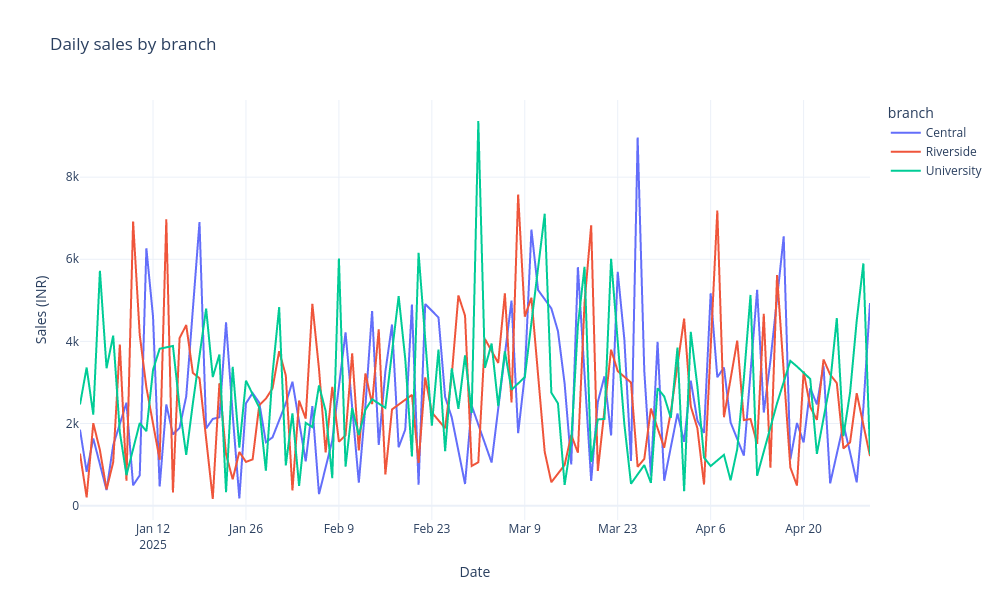

In [18]:
fig = px.line(
    daily, x='date', y='bill_amount', color='branch',
    title='Daily sales by branch', labels={'date': 'Date', 'bill_amount': 'Sales (INR)'},
)
fig.update_layout(template='plotly_white')  # Styling only; no missing days are inserted.
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Each colored line connects that branch's observed daily totals. A line segment across an absent date is not a recorded value for that date. The chart provides timing and scale context, but it does not normalize by capacity or estimate a sales forecast. The `daily` table printed in Step 15 lets you trace a plotted point to its exact grouped amount.

### Step 17 - Plot wait and rating while retaining order-level context

**Question:** What individual-order pattern lies behind the correlation coefficient?

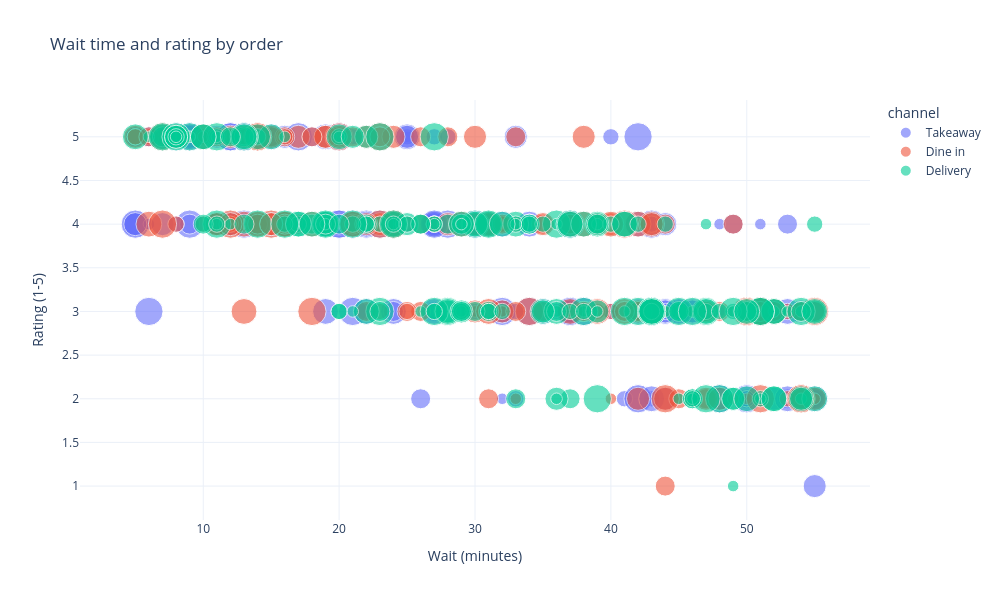

In [19]:
# Preserve one point per order; color and bubble size add channel and party-size context.
fig = px.scatter(
    filtered, x='wait_minutes', y='rating', color='channel', size='guests',
    hover_data=['order_id', 'branch', 'bill_amount'], opacity=0.6,
    title='Wait time and rating by order',
    labels={'wait_minutes': 'Wait (minutes)', 'rating': 'Rating (1-5)'},
)
fig.update_layout(template='plotly_white')
# Render this figure directly in the notebook output.
display(fig)

**Interpretation and reasoning**

Every point is an order. Channel controls color and guest count controls bubble size; hover in an interactive notebook identifies the source order. Discrete ratings create overlapping bands, and opacity helps show density. Bubble size does not make the Pearson calculation guest-weighted. The chart shows association and context, but cannot identify the operational cause of a low rating.

### Step 18 - Inspect the distribution of bill amounts

**Question:** Is the average bill representative of an ordinary order?

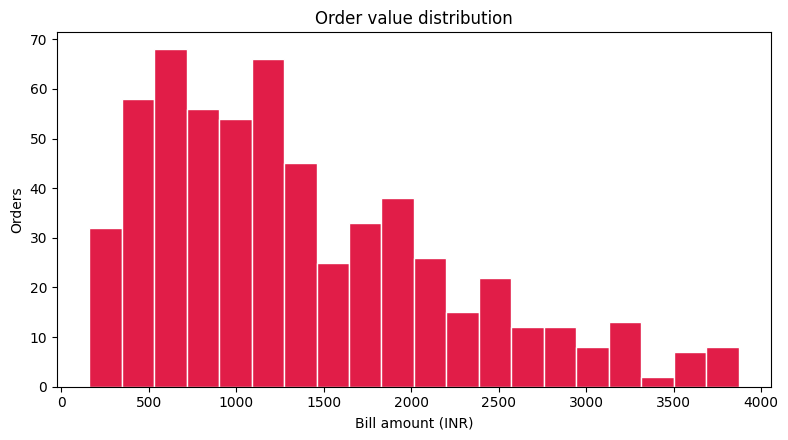

In [20]:
# The histogram counts orders within bill ranges rather than summing sales inside each range.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(filtered['bill_amount'], bins=20, color='#e11d48', edgecolor='white')
ax.set(title='Order value distribution', xlabel='Bill amount (INR)', ylabel='Orders')
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The histogram counts orders in each bill range. Large-party bills can create a right-hand tail and lift the mean, so a high bill does not necessarily mean higher spending per guest. The 20-bin choice changes the display detail rather than the data. The original app displays Matplotlib figures through `st.pyplot(fig)` and closes them with `plt.close(fig)` to avoid accumulating resources across reruns.

### Step 19 - Compare typical waits and variability across meal periods

**Question:** Which service periods show longer or more variable waits?

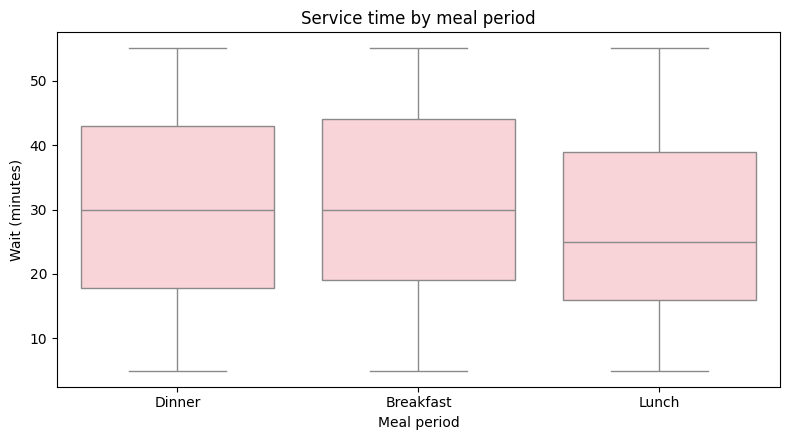

In [21]:
# The boxes summarize individual waits within each meal period; they do not show totals.
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=filtered, x='meal_period', y='wait_minutes', ax=ax, color='#fecdd3')
ax.set(title='Service time by meal period', xlabel='Meal period', ylabel='Wait (minutes)')
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The middle line is the median and the box spans the middle half. Default whiskers reach observations within 1.5 interquartile ranges; more distant points are retained as observations. This compares distributions rather than just means. Branches, channels, and party sizes are mixed within each period, so the difference is not a direct estimate of staffing performance.

### Step 20 - Locate subgroup ratings in a fixed-scale heatmap

**Question:** Which branch/meal-period combinations deserve a closer look at customer experience?

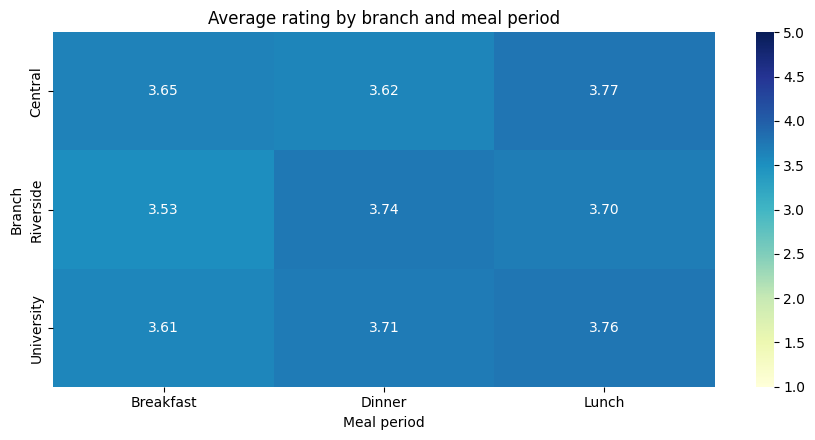

In [22]:
rating_grid = filtered.pivot_table(
    index='branch', columns='meal_period', values='rating', aggfunc='mean'
)  # A cell is an order-weighted mean score for one observed combination.
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(rating_grid, annot=True, fmt='.2f', vmin=1, vmax=5, cmap='YlGnBu', ax=ax)
ax.set(title='Average rating by branch and meal period', xlabel='Meal period', ylabel='Branch')
fig.tight_layout()
# Render this figure directly in the notebook output.
display(fig)
plt.close(fig)  # The saved output remains visible; release the open figure handle.

**Interpretation and reasoning**

The cell numbers are scores out of five, not correlation coefficients. Fixed limits from one to five keep colors comparable across selections, but small differences may look subtle and are not automatically meaningful. Inspect the sample counts from the earlier cell alongside the means. Missing combinations remain missing rather than receiving a zero score; wholly unobserved labels can be absent from the pivot axes.

## Inspect, report, and investigate

### Step 21 - Summarize distributions of the actual numeric columns

**Question:** Which numeric values and spreads should we inspect before telling the story?

In [23]:
# Keep numeric fields only, then report their order-level counts, center, spread, and extremes.
numeric_summary = filtered.select_dtypes(include='number').describe().round(2)
print(numeric_summary.to_string())

       guests  bill_amount  food_cost  wait_minutes  rating  contribution
count  600.00       600.00     600.00        600.00  600.00        600.00
mean     3.46      1368.34     378.49         29.56    3.67        989.85
std      1.68       845.54     202.08         14.66    0.95        718.82
min      1.00       161.68      70.13          5.00    1.00         14.42
25%      2.00       676.59     211.99         17.00    3.00        438.18
50%      3.00      1177.32     354.16         29.00    4.00        804.54
75%      5.00      1894.42     533.61         42.00    4.00       1393.82
max      6.00      3870.32     898.57         55.00    5.00       3316.21


**Interpretation and reasoning**

`describe()` summarizes the selected order-level columns, including the derived contribution. Count is available measurements, mean is the arithmetic average, standard deviation measures spread, and the quartiles locate parts of the ordered distribution. Do not compare unlike units as if their numeric magnitudes had the same meaning: minutes, guests, INR, and rating points are different quantities.

### Step 22 - Generate a short report from calculated values

**Question:** How can the program produce a readable finding from the same values as the charts?

In [24]:
# Tutorial-sized reconstruction: the original app assembles 12 richer report sections.
scope = f'{len(filtered)} selected orders; {start_date} to {end_date} inclusive'
finding = (
    f'Sales are INR {sales:,.2f} across {guests:,} guest appearances. '
    f'Food-cost contribution is INR {filtered["contribution"].sum():,.2f} before other costs.'
)
report_parts = [
    '# Restaurant operations - teaching report',
    '## Scope\n' + scope,
    '## Commercial result\n' + finding,
    f'## Service\nMean wait: {average_wait:.2f} minutes; median: {median_wait:.2f}; p90: {p90_wait:.2f}.',
    f'## Ratings\nMean score: {average_rating:.2f}/5; wait/rating correlation: {association:.2f}.',
    '## Limit\nThese fictional associations do not establish the cause of service or rating differences.',
]
teaching_report = '\n\n'.join(report_parts)
print(teaching_report)

# Restaurant operations - teaching report

## Scope
600 selected orders; 2025-01-01 to 2025-04-30 inclusive

## Commercial result
Sales are INR 821,005.18 across 2,075 guest appearances. Food-cost contribution is INR 593,911.88 before other costs.

## Service
Mean wait: 29.56 minutes; median: 29.00; p90: 50.00.

## Ratings
Mean score: 3.67/5; wait/rating correlation: -0.74.

## Limit
These fictional associations do not establish the cause of service or rating differences.


**Interpretation and reasoning**

The f-strings insert current numbers into defined sentences; the list and join operation build Markdown. No AI model or external service writes the finding. This shorter report demonstrates the original app's assembly technique rather than replacing its complete report. The actual app also includes all chart guides, formulas, quality checks, next steps, and limitations, then uses one shared string for display and download.

### Step 23 - Inspect the exact selected CSV payload

**Question:** Which observations can a reader use to reproduce or check the analysis?

In [25]:
csv_text = filtered.to_csv(index=False)    # Include contribution, omit pandas row labels.
print('\n'.join(csv_text.splitlines()[:5]))  # Preview the header and first four orders.
print(f'Data records in the export: {len(filtered)}')

order_id,date,branch,meal_period,channel,guests,bill_amount,food_cost,wait_minutes,rating,contribution
DINE-0001,2025-01-01,Central,Dinner,Takeaway,1,470.12,102.74,54,3,367.38
DINE-0002,2025-01-02,University,Breakfast,Dine in,3,1242.74,381.17,47,3,861.5699999999999
DINE-0003,2025-01-03,Central,Lunch,Delivery,3,1430.24,370.61,34,4,1059.63
DINE-0004,2025-01-04,University,Dinner,Dine in,6,1858.33,809.89,55,3,1048.44
Data records in the export: 600


**Interpretation and reasoning**

This is the actual unrounded CSV string from the selected DataFrame. It includes source fields plus contribution and retains one row per order. It does not include the separate branch-summary or heatmap tables. Long decimal tails can reflect binary floating-point subtraction; the original app exports the same unrounded working values. The source CSV remains untouched.

### Step 24 - Recalculate a specific operational question

**Question:** What changes when we inspect one branch and one meal period instead of mixing all orders?

In [26]:
# Build a separate scenario so the default filtered table remains unchanged.
scenario = frame[
    (frame['branch'] == 'University') & (frame['meal_period'] == 'Dinner')
].copy()
print(f'Scenario: University / Dinner | Orders: {len(scenario)}')
print(f'Sales: INR {scenario["bill_amount"].sum():,.2f}')
print(f'Mean wait: {scenario["wait_minutes"].mean():.2f} minutes')
print(f'Median wait: {scenario["wait_minutes"].median():.2f} minutes')
print(f'90th-percentile wait: {scenario["wait_minutes"].quantile(0.9):.2f} minutes')
print(f'Mean rating: {scenario["rating"].mean():.2f}/5')

Scenario: University / Dinner | Orders: 58
Sales: INR 83,582.52
Mean wait: 31.59 minutes
Median wait: 34.00 minutes
90th-percentile wait: 50.30 minutes
Mean rating: 3.71/5


**Interpretation and reasoning**

Parentheses define each condition, and `&` combines them elementwise. This group has 58 observed orders. The source app reaches the same population with its branch and meal-period widgets, retaining the full date window. The result can guide an investigation, but channel, party size, staffing, and unrecorded customer expectations can still differ within or between groups.

### Step 25 - Add a channel comparison as an explicit extension

**Question:** Could order channel be relevant context when comparing branch experiences?

In [27]:
# Extension: the original app colors points by channel but does not show this summary table.
channel_summary = filtered.groupby('channel').agg(
    orders=('order_id', 'size'),
    sales=('bill_amount', 'sum'),
    guests=('guests', 'sum'),
    average_wait=('wait_minutes', 'mean'),
    average_rating=('rating', 'mean'),
)
channel_summary['sales_per_guest'] = channel_summary['sales'].div(
    channel_summary['guests'].replace(0, float('nan'))
)
print(channel_summary.round(2).to_string())

          orders      sales  guests  average_wait  average_rating  sales_per_guest
channel                                                                           
Delivery     200  268089.82     691         31.20            3.58           387.97
Dine in      208  277998.93     704         29.13            3.73           394.88
Takeaway     192  274916.43     680         28.32            3.70           404.29


**Interpretation and reasoning**

This added table repeats the same principles at a new grain: counts beside means and a ratio of totals for sales per guest. It is not an existing sidebar filter or proof that channel causes a difference. To add a channel widget later, apply its `.isin()` mask before deriving metrics and before the final empty-data guard, so every downstream output uses the new selection consistently.

## Build the Streamlit application

The analysis does not need a separate spreadsheet step before becoming a web interface. Streamlit widgets return ordinary Python values, pandas uses them to select records, and display calls present the calculated values. The program runs on the server machine while the viewer uses a browser.

The complete Streamlit reference script below is a **compact reconstruction**, with the original filter dimensions, KPI definitions, all five chart types, a selected-record export, and a shorter Markdown report. The existing `app.py` additionally contains detailed context, visual explanations, source-quality panels, and its 12-section report. Copy only the Python code inside the reference block into `practice_app.py` beside `restaurant_orders.csv` and run it separately:

```bash
python -m streamlit run practice_app.py
```

Use `--server.port 8502` in a workshop workspace when its built-in dashboard uses 8501, then open the forwarded port. This reference script is self-contained and does not rely on variables created in the earlier notebook cells.

### Checkpoint: make a reproducible interactive answer

**Predict:** Which outputs must change after a branch selection? What should an empty selection display?

**Inspect:** Locate the guards, cards, charts, and download calls in the Streamlit reference script. Inspect the runnable AppTest results for the original app.

**Explain:** How would you reproduce a surprising browser result in the notebook? Include selections, formulas, and source row checks.

### Step 26 - Turn the analysis into an interactive operations dashboard

**Question:** How can someone explore the same calculations through controls, charts, and downloads?

## Connect the calculations to the original app

The Streamlit teaching script is a compact reference to save separately. Runnable AppTest cells inspect the original [app.py](app.py) without starting a server. The original also contains context, definitions, chart explanations, and a longer report.

| Notebook object or operation | Original app connection |
| --- | --- |
| `selected_branches`, `selected_meals` | **Branches** and **Meal periods** widgets return `selected_branch` and `selected_meal_period`. The original app has no channel filter. |
| `start_date`, `end_date`, and the masks | **Date range** returns `dates`; these selections create `filtered`. |
| `sales` and selected column means | Four cards show Sales, Average bill, Average wait, and Average rating. |
| Derived `contribution` | Appears in the selected records, branch table, and calculated findings; it subtracts food cost only. |
| `daily` and order-level observations | **Operations dashboard** displays daily branch sales, wait/rating scatter, and branch summaries. |
| Bill/wait distributions and rating pivot | **Explore the data** contains the histogram, meal-period boxplot, and branch/meal heatmap. |
| Selected rows and the complete source | **Data and quality** downloads `filtered` with contribution but summarizes source quality from `frame`. |
| Findings, scope, and `cell_counts` | `insights` and `scope` feed the full report. A separate sample-count table appears below the rendered report; that table is not embedded in its Markdown download. |

The notebook's `branch_summary` uses descriptive average-column names. The original findings table uses `wait` and `rating`; its displayed branch table uses `average_wait` and `rating`. Match calculations, not variable spelling alone.

Notebook variables persist until overwritten or the kernel restarts; rerun downstream cells after changing selections. Streamlit sidebar changes normally rerun calculations and all tabs with current selections. The CSV is reread on a rerun, not continuously watched. Hovering, zooming, sorting a displayed table, or switching tabs does not change which orders the sidebar selects.

### Complete Streamlit teaching script - reference

The following complete script is shown in a **Markdown reference cell**. It is intended for the separate `.py` file described above, because Streamlit renders controls and pages through its own server execution. The analysis cells in this notebook have already calculated and explained the measures used here.

```python
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import streamlit as st

st.set_page_config(page_title='Restaurant Operations Dashboard', layout='wide')
st.title('Restaurant Operations Dashboard')
st.caption('Fictional teaching orders | Currency: INR | Ratings: 1-5')

# A saved script finds its own sibling CSV, even if launched from another directory.
data_file = Path(__file__).resolve().with_name('restaurant_orders.csv')
try:
    frame = pd.read_csv(data_file)
    frame['date'] = pd.to_datetime(frame['date'], errors='raise')
    required = ['order_id', 'date', 'branch', 'meal_period', 'channel',
                'guests', 'bill_amount', 'food_cost', 'wait_minutes', 'rating']
    if not set(required).issubset(frame.columns) or frame.empty:
        raise ValueError('Provide all required columns and at least one order.')
    for column in ['guests', 'bill_amount', 'food_cost', 'wait_minutes', 'rating']:
        frame[column] = pd.to_numeric(frame[column], errors='raise')
    if frame[required].isna().any().any():
        raise ValueError('Fill missing required values first.')
except (OSError, ValueError, KeyError) as error:
    st.error(f'Could not load the dataset: {error}')
    st.stop()

def ratio(numerator, denominator):
    return numerator / denominator if denominator else 0.0

# Widget values feed the analysis; the widgets themselves do not change frame.
branches_chosen = st.sidebar.multiselect(
    'Branches', sorted(frame['branch'].unique()),
    default=sorted(frame['branch'].unique()), key='practice_restaurant_branches',
)
meals_chosen = st.sidebar.multiselect(
    'Meal periods', sorted(frame['meal_period'].unique()),
    default=sorted(frame['meal_period'].unique()), key='practice_restaurant_meals',
)
dates = st.sidebar.date_input(
    'Date range', (frame['date'].min().date(), frame['date'].max().date()),
    min_value=frame['date'].min().date(), max_value=frame['date'].max().date(),
    key='practice_restaurant_dates',
)
if len(dates) != 2:
    st.info('Choose both a start and an end date.')
    st.stop()
filtered = frame[
    frame['branch'].isin(branches_chosen)
    & frame['meal_period'].isin(meals_chosen)
    & frame['date'].dt.date.between(dates[0], dates[1])
].copy()
if filtered.empty:
    st.info('No orders match these filters.')
    st.stop()

# Calculate only after the complete selection and its empty-data guard.
filtered['contribution'] = filtered['bill_amount'] - filtered['food_cost']
sales = filtered['bill_amount'].sum()
cards = st.columns(4)
cards[0].metric('Sales (INR)', f'{sales:,.0f}')
cards[1].metric('Average bill (INR)', f'{filtered["bill_amount"].mean():,.0f}')
cards[2].metric('Average wait', f'{filtered["wait_minutes"].mean():.1f} min')
cards[3].metric('Average rating', f'{filtered["rating"].mean():.2f} / 5')
st.caption('Contribution excludes staffing, rent, delivery fees and tax. Observed associations are not causal effects.')

branch_summary = filtered.groupby('branch').agg(
    orders=('order_id', 'size'), sales=('bill_amount', 'sum'),
    contribution=('contribution', 'sum'), average_wait=('wait_minutes', 'mean'),
    average_rating=('rating', 'mean'),
)
daily = filtered.groupby(['date', 'branch'], as_index=False)['bill_amount'].sum()
cell_counts = filtered.groupby(['branch', 'meal_period']).size()

# Tabs determine placement; their code still runs during a normal full rerun.
dashboard, explore, records, report_tab = st.tabs(['Dashboard', 'Explore', 'Data', 'Report'])
with dashboard:
    st.plotly_chart(px.line(daily, x='date', y='bill_amount', color='branch',
                           title='Daily sales by branch'), use_container_width=True)
    st.plotly_chart(px.scatter(filtered, x='wait_minutes', y='rating', color='channel',
                              size='guests', hover_data=['order_id', 'branch', 'bill_amount'],
                              opacity=0.6, title='Wait time and rating'), use_container_width=True)
    st.dataframe(branch_summary.round(2))
with explore:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(filtered['bill_amount'], bins=20, color='#e11d48', edgecolor='white')
    ax.set(title='Order value distribution', xlabel='Bill (INR)', ylabel='Orders')
    st.pyplot(fig)
    plt.close(fig)  # Do not accumulate Matplotlib figures across widget reruns.
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=filtered, x='meal_period', y='wait_minutes', ax=ax, color='#fecdd3')
    ax.set_title('Service time by meal period')
    st.pyplot(fig)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(9, 4))
    grid = filtered.pivot_table(index='branch', columns='meal_period', values='rating', aggfunc='mean')
    sns.heatmap(grid, annot=True, fmt='.2f', vmin=1, vmax=5, cmap='YlGnBu', ax=ax)
    ax.set_title('Mean rating by branch and meal period')
    st.pyplot(fig)
    plt.close(fig)
with records:
    st.dataframe(filtered, hide_index=True)
    st.download_button('Download filtered CSV', filtered.to_csv(index=False),
                       'filtered_restaurant_orders.csv', 'text/csv')

# A short report uses the same selected totals; the original provides 12 sections.
report = '\n\n'.join([
    '# Restaurant operations',
    f'Selected orders: {len(filtered)}; requested dates: {dates[0]} to {dates[1]}.',
    f'Sales: INR {sales:,.2f}; food-cost contribution: INR {filtered["contribution"].sum():,.2f}.',
    f'Sales per guest: INR {ratio(sales, filtered["guests"].sum()):,.2f}.',
    f'Median wait: {filtered["wait_minutes"].median():.1f}; p90 wait: {filtered["wait_minutes"].quantile(0.9):.1f} minutes.',
    'Contribution is not net profit; observed service patterns do not establish their cause.',
])
with report_tab:
    st.download_button('Download teaching report', report, 'restaurant_teaching_report.md', 'text/markdown')
    st.markdown(report)
    st.subheader('Orders supporting branch/meal-period comparisons')
    st.dataframe(cell_counts.rename('orders').reset_index(), hide_index=True)
```

## Inspect the actual Streamlit application from this notebook

The companion script above is a compact teaching reconstruction. The next executable cells inspect the **existing sibling `app.py`**, which also contains the complete business context, chart explanations and full report.

`AppTest` is Streamlit's testing interface. It runs the application and lets Python inspect the UI elements it produced. It does not start a browser server. We use it here to connect the notebook's calculations with the application's real labels and values. The displayed tables summarize application elements; they are not browser screenshots.

### Load and run the sibling app

`AppTest.from_file(...)` reads a saved Streamlit script; `.run()` executes it with default widget values. The checks stop this cell if the app raises an exception or displays a loading error. Keeping `app.py` beside its CSV lets its `Path(__file__)` lookup work independently of notebook variables.

In [28]:
from streamlit.testing.v1 import AppTest  # Inspect Streamlit output without launching a server.
import logging

# AppTest intentionally runs without a browser session; quiet its context-only warning.
# Application errors are still checked explicitly below.
logging.getLogger('streamlit.runtime.scriptrunner_utils.script_run_context').setLevel(logging.ERROR)

app_file = PROJECT_DIR / 'app.py'
app_preview = AppTest.from_file(str(app_file), default_timeout=45).run()
if len(app_preview.exception):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.exception))
if len(app_preview.error):
    raise RuntimeError('; '.join(str(error.value) for error in app_preview.error))

print('Script:', app_file.name)
print('Title:', app_preview.title[0].value)
print('Default application run completed.')

Script: app.py
Title: Restaurant Operations Dashboard
Default application run completed.


### Read the controls, KPI cards and output containers

The values below come from the application instance that just ran. A metric element has a `label` and a formatted `value`; a multiselect has the current list of choices. The table dimensions describe what the app actually rendered. Chart counts distinguish interactive Plotly figures from Matplotlib/Seaborn images.

In [29]:
# Turn rendered KPI cards into an ordinary table we can inspect in the notebook.
baseline_cards = {metric.label: metric.value for metric in app_preview.metric}
display(pd.DataFrame(baseline_cards.items(), columns=['Dashboard measure', 'Displayed value']))

for widget in app_preview.multiselect:
    print(widget.label + ': ' + ', '.join(map(str, widget.value)))
for widget in app_preview.date_input:
    print(widget.label + ': ' + ' to '.join(map(str, widget.value)))
for widget in app_preview.slider:
    print(widget.label + ': ' + str(widget.value))
for index, table in enumerate(app_preview.dataframe, start=1):
    print(f'Table {index}: {len(table.value)} rows x {len(table.value.columns)} columns')
print('Interactive Plotly charts:', len(app_preview.get('plotly_chart')))
print('Rendered statistical charts:', len(app_preview.get('imgs')))
for button in app_preview.get('download_button'):
    print('Download:', button.proto.label)

,Dashboard measure,Displayed value
0,Sales (INR),"821,005"
1,Average bill (INR),"1,368"
2,Average wait,29.6 min
3,Average rating,3.67 / 5


Branches: Central, Riverside, University
Meal periods: Breakfast, Dinner, Lunch
Date range: 2025-01-01 to 2025-04-30
Table 1: 6 rows x 3 columns
Table 2: 3 rows x 5 columns
Table 3: 10 rows x 2 columns
Table 4: 600 rows x 11 columns
Table 5: 8 rows x 6 columns
Table 6: 10 rows x 3 columns
Table 7: 9 rows x 3 columns
Interactive Plotly charts: 2
Rendered statistical charts: 3
Download: Download filtered CSV
Download: Download full report (Markdown)


### Change one filter and observe a real app rerun

This cell selects one value in the first multiselect and compares the resulting KPI cards with the baseline. `.set_value(...)` changes the control; `.run()` executes the app again. We then restore the complete selection so the preview ends in its default state.

The notebook's own `frame` and `filtered` variables belong to the analysis session. `AppTest` executes the script in its own application context, so changing this preview does not silently alter the earlier notebook analysis. In the live browser app, the corresponding widget interaction triggers the rerun for you.

In [30]:
# Keep all original choices so the application can be restored after this experiment.
first_control = app_preview.multiselect[0]
original_choices = list(first_control.value)
one_choice = original_choices[0]
control_label = first_control.label

# This is the programmatic equivalent of narrowing a sidebar multiselect.
first_control.set_value([one_choice]).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The narrowed app selection did not complete successfully.')
selected_cards = {metric.label: metric.value for metric in app_preview.metric}
comparison = pd.DataFrame({
    'Dashboard measure': list(baseline_cards),
    'All choices': list(baseline_cards.values()),
    f'{control_label}: {one_choice}': [selected_cards[label] for label in baseline_cards],
})
display(comparison)

# Restore the baseline; the notebook data and the source CSV have not been edited.
app_preview.multiselect[0].set_value(original_choices).run()
if len(app_preview.exception) or len(app_preview.error):
    raise RuntimeError('The application could not restore its original selection.')
print('Restored', control_label + ':', ', '.join(map(str, original_choices)))

,Dashboard measure,All choices,Branches: Central
0,Sales (INR),"821,005","268,252"
1,Average bill (INR),"1,368","1,369"
2,Average wait,29.6 min,29.0 min
3,Average rating,3.67 / 5,3.67 / 5


Restored Branches: Central, Riverside, University


### Open the browser interface

In a **terminal in this project folder**, run:

```bash
python -m streamlit run app.py --server.port 8502
```

Open the displayed local URL, or forward port 8502 in Cloud Labs. The built-in workshop dashboard uses port 8501. Streamlit keeps running while the page is available; stop it with **Ctrl+C** in that terminal. This command is a terminal instruction, so **Run All** in this notebook does not start the server.

Follow one choice through the app: widget value → pandas row selection → derived columns → grouped results → cards/charts/report. This is the connection between the analysis and its browser interface.

## Understand the original app and its limits

The original [app.py](app.py) contains richer teaching text than the compact reconstruction. `CASE`, `DECISION`, and `DATA_CONTEXT` describe the manager's question and dataset; `FORMULAS` records metric definitions; `FIELD_GUIDE` documents columns. `VISUAL_GUIDE` supplies five-part explanations of each chart, and `explain_visual(index, container=st)` renders those explanations in the correct tab or column. These are reusable strings and collections, not additional data sources.

Its `insights` list includes the selected commercial total, sales-leading branch, longest mean wait, median/p90 wait, correlation interpretation, sales per guest, and subgroup-count caution. The first three answers appear near the top of the page, while all seven feed the report. `report_parts` combines strings, formatted values, tables, and explanations into 12 sections. `report_parts[5]` refers to **KPI results**, because the title is index zero; the original app appends the field dictionary there. One joined `full_report` string is used for both screen rendering and download.

The original report tab adds a complete branch/meal-period count table **after** displaying that string. Therefore the downloaded Markdown has the narrative minimum/count-below-20 summary but not the full separately rendered table. Its quality panel uses full `frame`, whereas the charts, cards, insights, numeric summary, and CSV export use `filtered`. Downloaded CSV rows include contribution; the original source file is untouched.

### Interpretation and input limits

- **Guest and order units:** Average bill is per order; sales per guest uses guest counts. Those counts are guest appearances, not unique people. An order mean rating is not guest-weighted or a satisfaction percentage.
- **Cost coverage:** Contribution subtracts food cost only. Staffing, rent, delivery fees, and tax remain outside it.
- **Correlation:** Pearson correlation is unitless association, not rating loss per minute or proof of cause. Constant or insufficient data makes it undefined. The app computes no uncertainty intervals or significance test.
- **Group mix:** Branch and meal-period differences can reflect channel and party-size differences. No staffing or capacity adjustment is performed. Twenty orders is an illustrative caution threshold, not a guarantee of reliability.
- **Missing observations:** Absent branch/date combinations are not automatically zero-sales days. Missing heatmap cells are not zero scores.
- **Validation:** The loader checks required columns, nonempty input, parseable dates/numbers, and missing required values. It does not enforce unique order IDs, finite amounts, positive integer guests, nonnegative waits, or ratings in the 1-5 range. A negative guest count can parse successfully and then fail as a Plotly marker size. Later calculations and charts are outside the loading `try` block.
- **Zero denominators and ties:** The scalar helper's zero fallback is a programming safeguard. `idxmax()` returns the first tied grouped label, so a named leader is not necessarily unique.
- **Source changes:** The static case text describes the bundled 600 orders. Replacing the CSV changes calculated outputs and scope but does not rewrite those narrative constants.

### Useful next investigations

Change branch or meal choices and rerun from the filter cell onward. Compare counts beside every mean. Inspect orders at or above the p90 wait threshold and notice that tied durations can include more than exactly 10% of records. Add a channel widget before the empty-state guard if you want a new analytical filter, then verify that all downstream outputs share it. Propose a specific service-change experiment and identify the staffing, process, cost, or customer-comment data it would require; the current dashboard helps choose that question but does not conduct the experiment.

If imports fail, verify the active environment. If the CSV cannot be found in a notebook, check the working directory; a saved app instead expects its named sibling CSV. Complete both date endpoints, retain at least one branch and meal selection, and save/rerun after editing input. An unavailable correlation may be correct for a constant or tiny selection rather than a software failure.

## References

- [Original app](app.py), [source CSV](restaurant_orders.csv), [workshop setup](../README.md), and [repository setup](../../README.md) establish implemented behavior and the observations used here.
- [pandas 2.2 introduction](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/10min.html), [grouping](https://pandas.pydata.org/pandas-docs/version/2.2/user_guide/groupby.html), [Series.quantile](https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.Series.quantile.html), and [Series.corr](https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.Series.corr.html) explain the analysis methods.
- [Streamlit run instructions](https://docs.streamlit.io/develop/concepts/architecture/run-your-app) and [Streamlit 1.50 tabs](https://docs.streamlit.io/1.50.0/develop/api-reference/layout/st.tabs) explain server execution and containers.
- [Plotly Express](https://plotly.com/python/plotly-express/), [Matplotlib histograms](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html), [Seaborn boxplots](https://seaborn.pydata.org/generated/seaborn.boxplot.html), and [Seaborn heatmaps](https://seaborn.pydata.org/generated/seaborn.heatmap.html) document the charting tools.

## Practice turning findings into useful next questions

1. **Investigate a branch without blaming it prematurely.** Compare channels within one branch and meal period. Calculate each channel's order count, mean wait, and mean rating. **Hint:** use a fresh filtered copy and keep the date window fixed. **Interpret:** Could order size or delivery processes explain a difference? What additional evidence would you collect before changing staffing?

2. **Describe the service tail.** Compare median and 90th percentile wait across meal periods within a branch, alongside counts. **Hint:** `quantile(0.9)` may interpolate and does not simply select the longest observed order; inspect the distribution too. **Interpret:** Would an improvement in the mean guarantee improvement for the slowest customers? What does the tail reveal?

3. **Add a contribution comparison.** Calculate each branch's summed contribution and contribution divided by sales. **Hint:** derive contribution on selected orders, divide grouped totals, and state what happens for a zero sales denominator. **Interpret:** Can a high contribution percentage establish that a branch is profitable? Name missing operating costs and explain the effect of sales volume.

Before presenting, state the order population and time window, label order versus guest denominators, show counts beside subgroup averages, distinguish contribution from profit, check a source record, and describe correlation as an association. Finish with a concrete next investigation and the evidence needed to evaluate it.

## Finish with an explanation you can defend

Before presenting the project, explain one complete chain in your own words: **the question, the source rows, the operation, the result, and the decision it informs**. State the units and denominator. Show a supporting table or chart and one limitation. Then restart the kernel and run the notebook from the top to confirm that the result does not depend on forgotten interactive state.

Notebook and application references: [Jupyter notebook structure](https://nbformat.readthedocs.io/en/latest/format_description.html), [Plotly notebook renderers](https://plotly.com/python/renderers/), and [Streamlit 1.50 AppTest](https://docs.streamlit.io/1.50.0/develop/api-reference/app-testing/st.testing.v1.apptest).